<a href="https://colab.research.google.com/github/KristenRoggenbauer/Airline_Satisfaction/blob/main/Roggenbauer_Airline_Submissions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Airline Satisfaction
### Kristen Roggenbauer

## The Problem

In today's world, flying is second-nature for so many people.
* Weekend getaway? Take a quick flight!
* Going across the country for work? Hop on a plane!
* Happy Holidays! Time to fly to see the family!

Millions of people fly each year to many places for many reasons, with a variety of different wants, needs, and goals.

However, to an airline, the goal is the same for each passenger:

<center><b>Get the passenger where they need to go safely, and get them there satisfied and happy, ready to book another flight.</b></center>

Getting them there safely? That's the easy part. But ensuring they make it there happy... to do that, we need to understand a whole different issue.

<center><b>What makes a passenger satisfied when on a flight?</b></center>

To do this, one must predict satisfaction, the response variable, using a variety of predictors.

In [28]:
# code to export notebook as .html for Canvas upload

from google.colab import drive
from google.colab import files

drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [29]:
!pip install ISLP

In [30]:
import numpy as np
import pandas as pd
import os
from ISLP.models import (ModelSpec as MS,
                         summarize)
from sklearn.linear_model import LogisticRegression
from ISLP import confusion_table
from ISLP.models import contrast
from sklearn.discriminant_analysis import \
     (LinearDiscriminantAnalysis as LDA,
      QuadraticDiscriminantAnalysis as QDA)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
import statsmodels.api as sm
from sklearn.metrics import roc_auc_score
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
import seaborn as sns


In [31]:
#Get the files

file_path = '/content/drive/MyDrive/Colab Notebooks/DSC 420/Kaggle Airline Project/train.csv'
file_path2 = '/content/drive/MyDrive/Colab Notebooks/DSC 420/Kaggle Airline Project/test.csv'
data = pd.read_csv(file_path)
test_data = pd.read_csv(file_path2)


## Data Exploration

**Missing Values**
* This dataset was very clean
* 292 missing values, all within "Arrival Delay in Minutes"
* Because "Arrival Delay in Minutes" and "Departure Delay in Minutes" appear very correlated, I decided the model likely only requires one of these. I removed "Arrival Delay in Minutes" from the analysis because of the missing values within it, with the assumption that "Departure Delay in Minutes" would be good enough to handle it. Another option would be simply removing these missing values, but I'm unaware if they are related to each other in some way (same airport, same company, etc).

**Examine the Variables**
* Used a correlation matrix
* Looked at the correlation between every (numerical) variable.
* Below are the largest correlations between predictor variables:
  * Arrival Delay in Minutes & Departure Delay in Minutes (0.842)
  * Seat comfort & Cleanliness (0.763)
  * Inflight entertainment & Cleanliness (0.751)
  * Seat comfort & Inflight entertainment (0.745)
  * Food and drink & Cleanliness (0.678)
* It appears that Seat Comfort, Cleanliness, and Inflight Entertainment are all highly correlated predictors.

**Response Distribution & Relationships**
* The distribution of the response variable (satisfaction) was 56% not satisfied, 44% satisfied.
* Age: satisfied customers appear to be slightly older than nonsatisfied customers
* Flight distance: people on longer flights appear to be more satisfied than people on shorter flights
* Ease of online booking: satisfied customers tended to rate ease of online booking slightly higher
* Food and drink: satisfied customers rated their food/drink options higher than nonsatisfied customers
* Online boarding: satisfied customers rated online boarding much higher than nonsatisfied customers
* Seat comfort: satisfied customers rated esat comfort much higher than nonsatisfied customers.
* Inflight entertainment: satisfied customers rate their inflight entertainment higher than nonsatisfied customers
* On-board service: satisfied customers rated the on-board service higher
* Leg Room: satisfied customers rated the leg room higher
* Baggage Handling: Satisfied customers rated baggage handling higher
* Checkin Service: Satisfied customers rated the checkin service higher
* Cleanliness: Satisfied customers rated the cleanliness higher
* Customer type: loyal customers seem more satisfied than disloyal customers (makes sense)
* Travel type: business travellers seem more satisfied than personal travellers
* Class: Business class seems more satisfied than eco and eco plus classes.
* The other variables did not seem to have much or any relationship with satisfaction.

Based on this exploration, I feel logistic regression may not be the best approach, as the variables do not appear normally distributed. Though, many variables do seem to somewhat relate with satisfaction. Those who do appear to relate seem to only have 1-2 points of difference, so I'm unsure if this will actually show up clearly in the logistic regression. However, I will still start with that as a baseline as it is extremely easy to perform and explain before trying to fully grasp new ideas to improve my models.

## Data Preparation - Missing Values + Categorical/Numerical Predictors

**Missing Values**

* The only missing values were located in the variable "Arrival Delay in Minutes"
* 292 missing values

Because "Arrival Delay in Minutes" and "Departure Delay in Minutes" appear very correlated, I decided the model likely only requires one of these. I removed "Arrival Delay in Minutes" from the analysis because of the missing values within it, with the assumption that "Departure Delay in Minutes" would be good enough to handle it. Another option would be simply removing these missing values, but I'm unaware if they are related to each other in some way (same airport, same company, etc).

**Categorical Data**
* Originally, the categorical variables were listed as "object" variables
  * Gender, Customer type, Travel type, and class
* I simply transformed them into 'category' type so the data could be properly converted to dummy variables later to use within the project

**Numerical Data**
* I examined the numerical data, as previously discussed in the Data Exploration section. However, I didn't transform any data and left it intact for interpretability and to keep the analysis straightforward. I wanted to dedicate more energy to the models themselves rather than transforming values to make data appear more normal.

Arrival Delay in Minutes    292
dtype: int64
Series([], dtype: int64)
                                         id       Age  Flight Distance  \
id                                 1.000000 -0.001780        -0.001213   
Age                               -0.001780  1.000000         0.190709   
Flight Distance                   -0.001213  0.190709         1.000000   
Inflight wifi service              0.000730  0.043137         0.046614   
Departure/Arrival time convenient -0.001701  0.050863        -0.036590   
Ease of Online booking            -0.000721  0.043831         0.087908   
Gate location                     -0.000524  0.004095         0.019533   
Food and drink                    -0.000644  0.048203         0.083711   
Online boarding                    0.000996  0.287612         0.310864   
Seat comfort                      -0.000571  0.229095         0.233666   
Inflight entertainment            -0.001029  0.130684         0.206140   
On-board service                  -0.00133

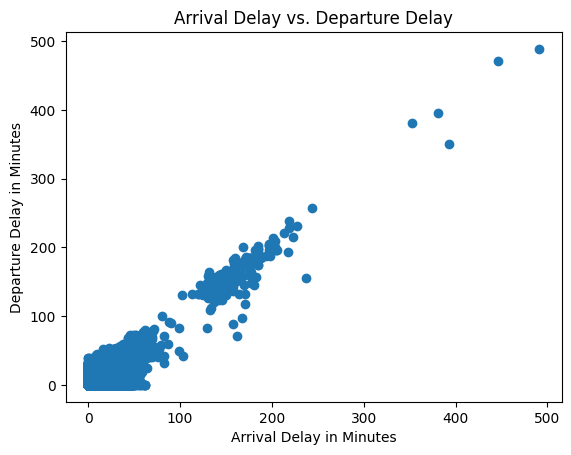

Index(['id', 'Age', 'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'Gender',
       'Customer Type', 'Type of Travel', 'Class', 'satisfaction'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 23 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   id                                 699635 non-null  int64  
 1   Age                                699635 non-null  int64  
 2   Flight Distance                    699635 non-null  int64  
 3   Inflight wifi service              699635 non-nul

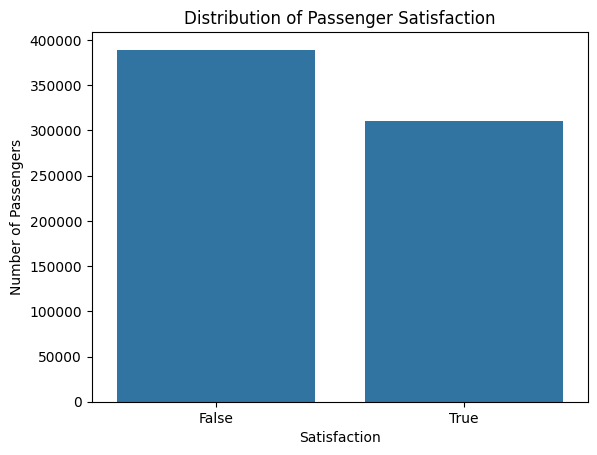

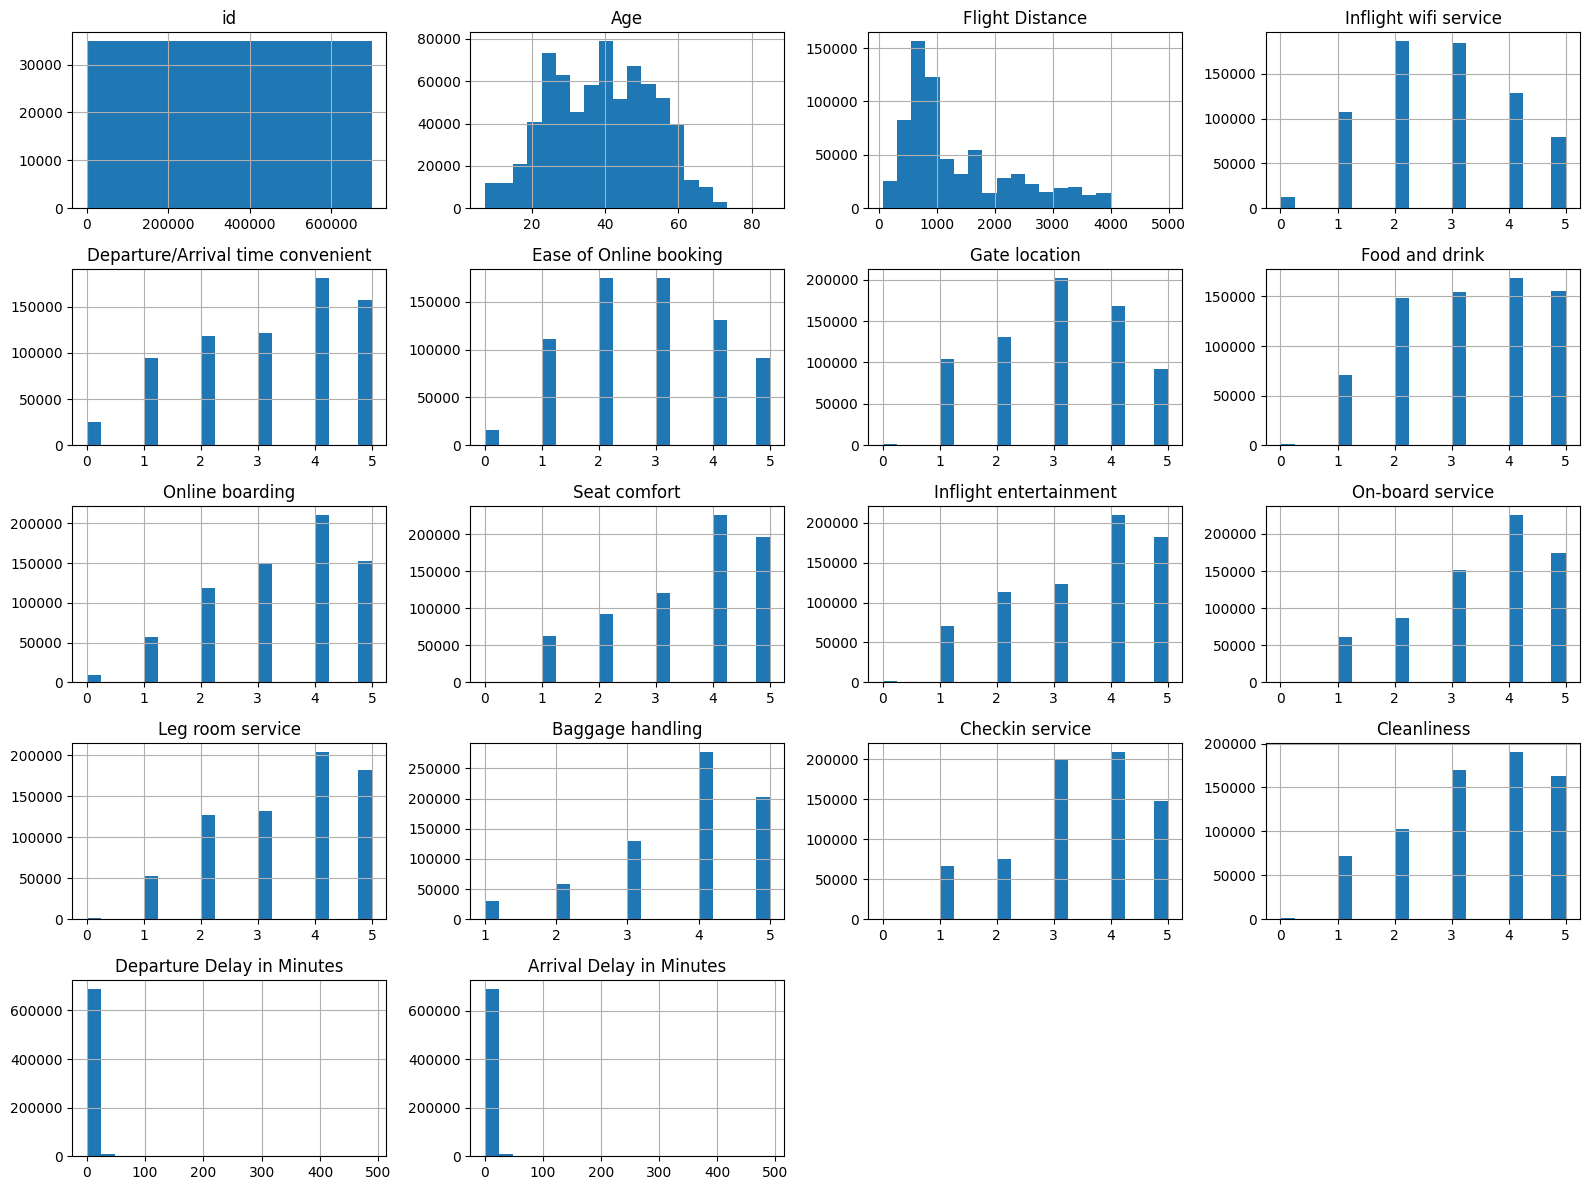

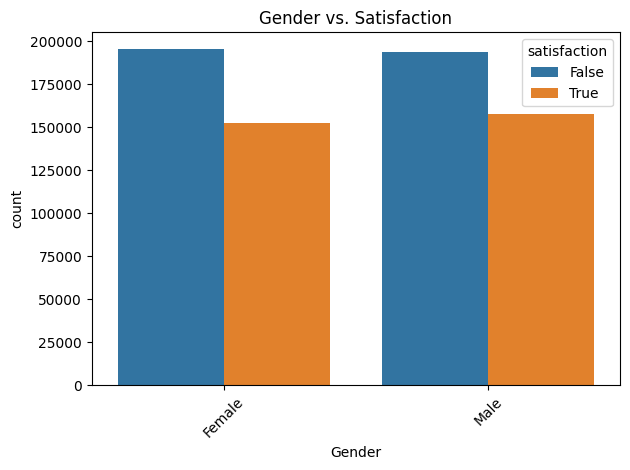

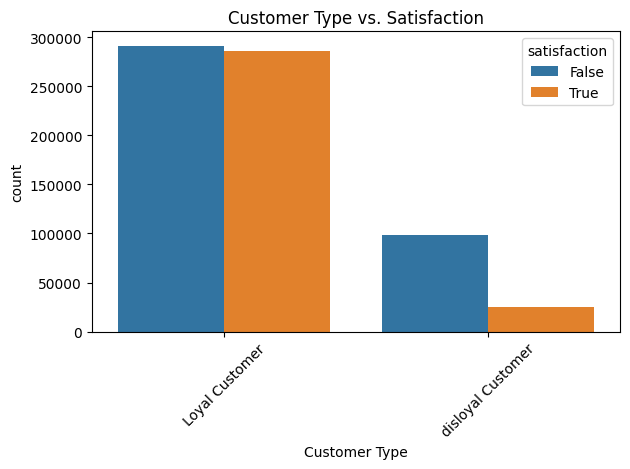

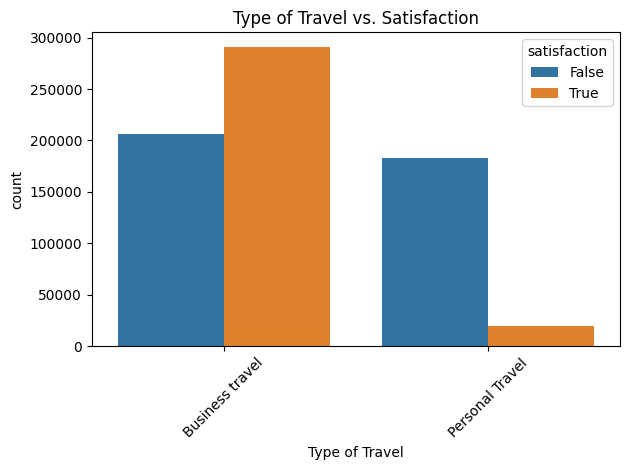

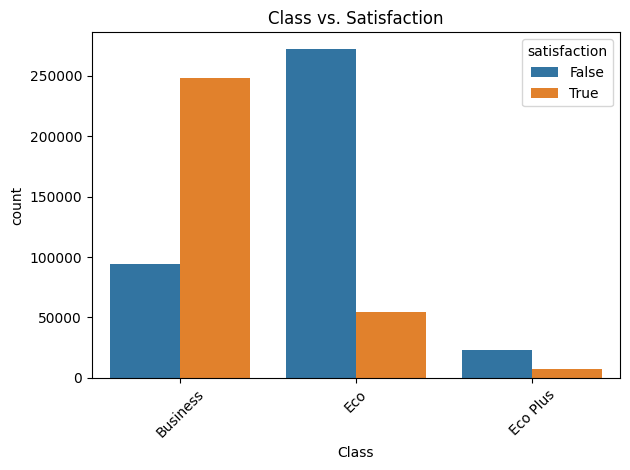

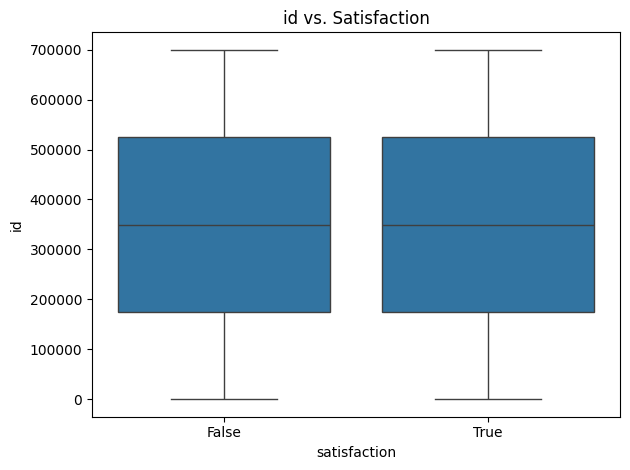

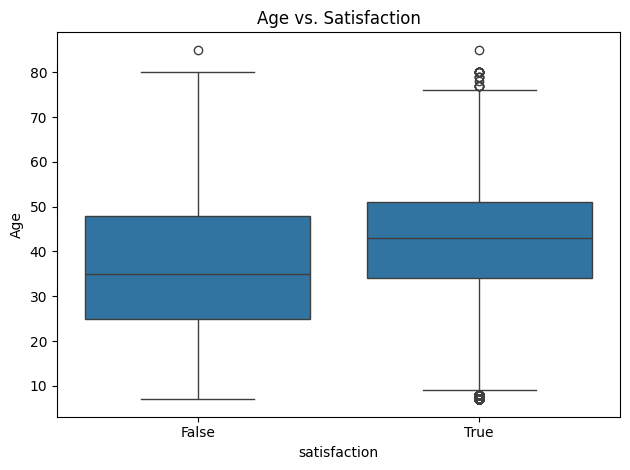

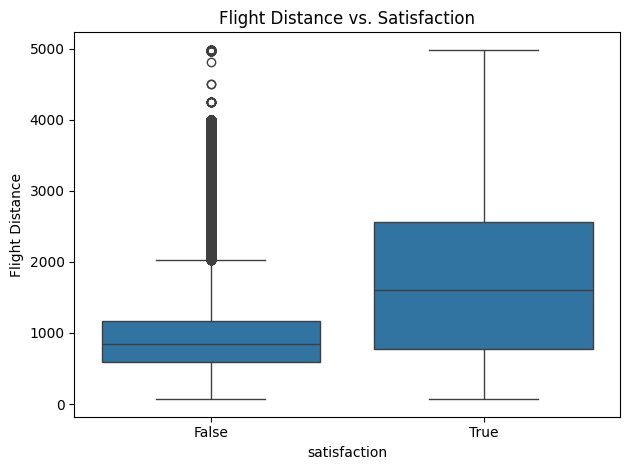

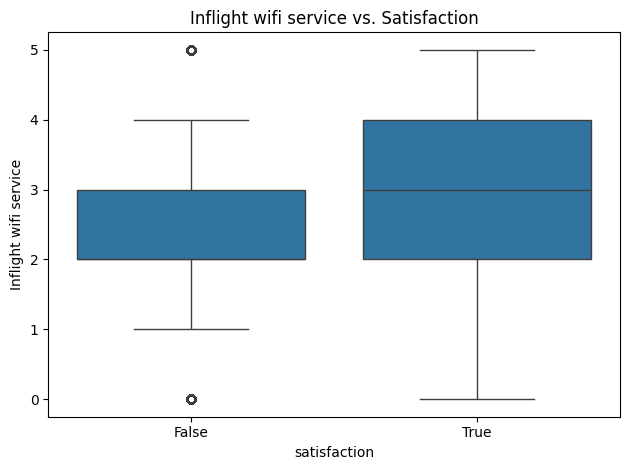

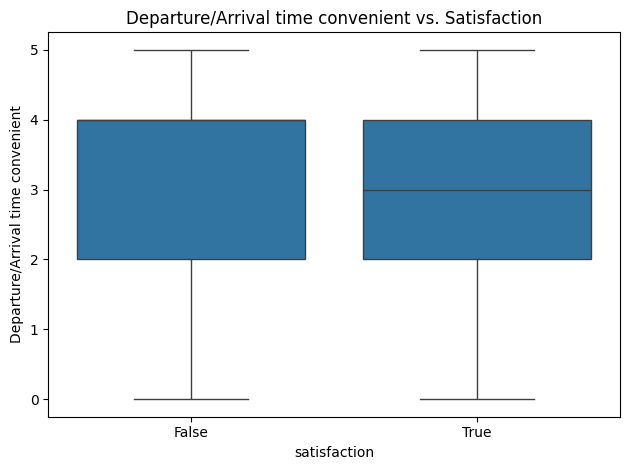

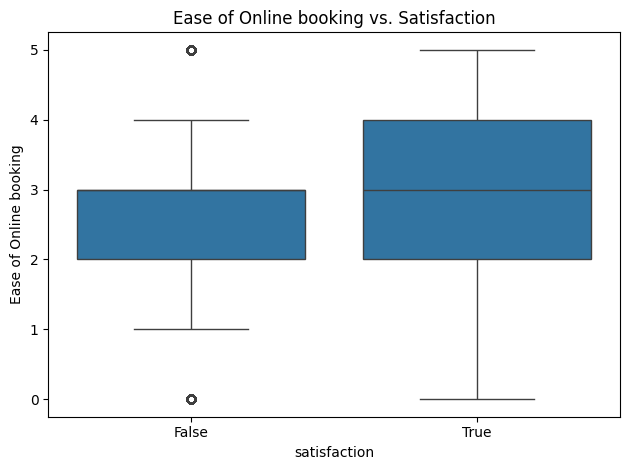

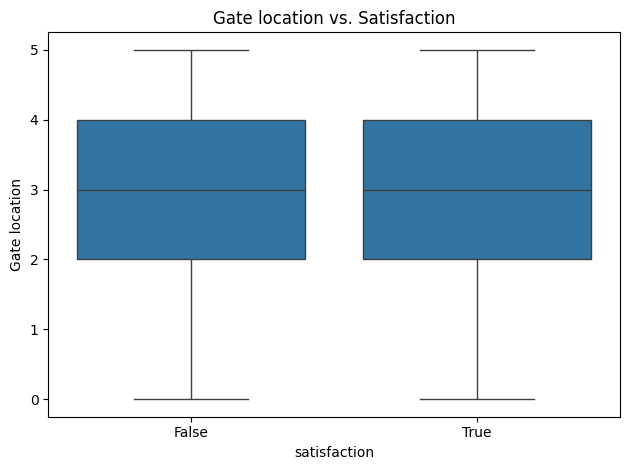

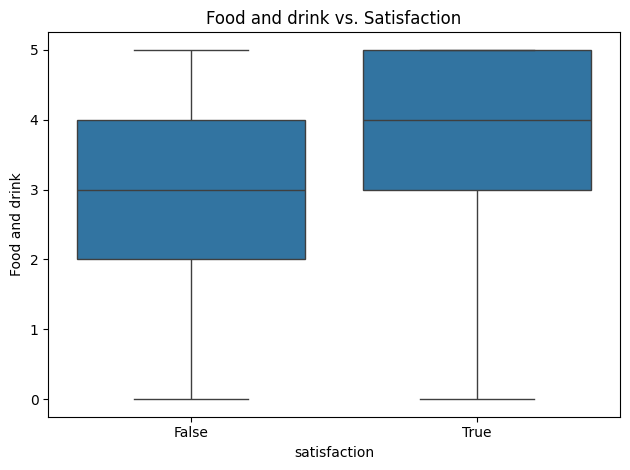

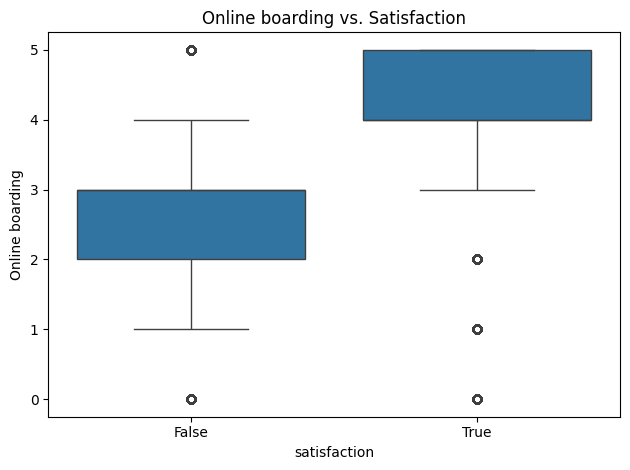

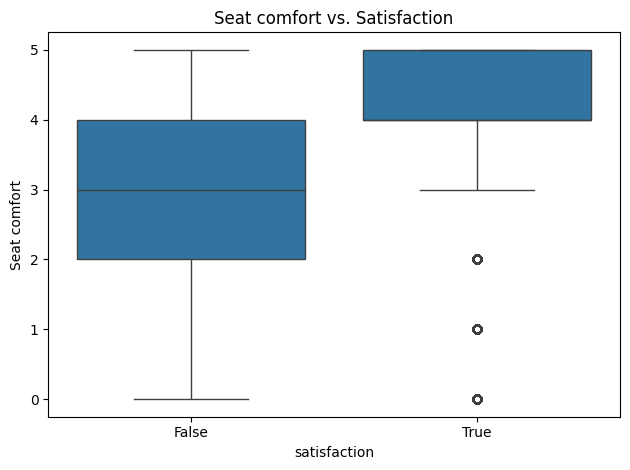

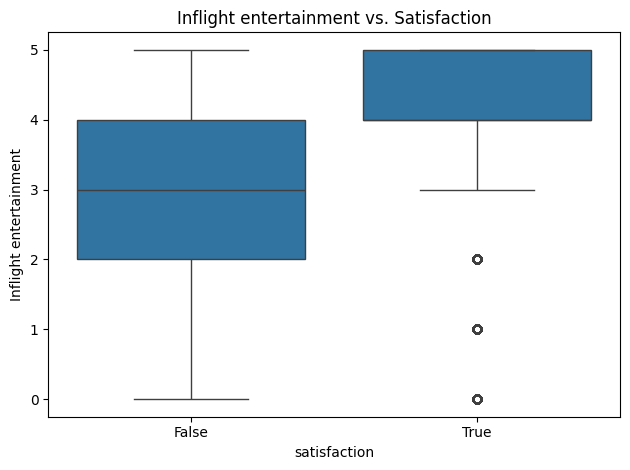

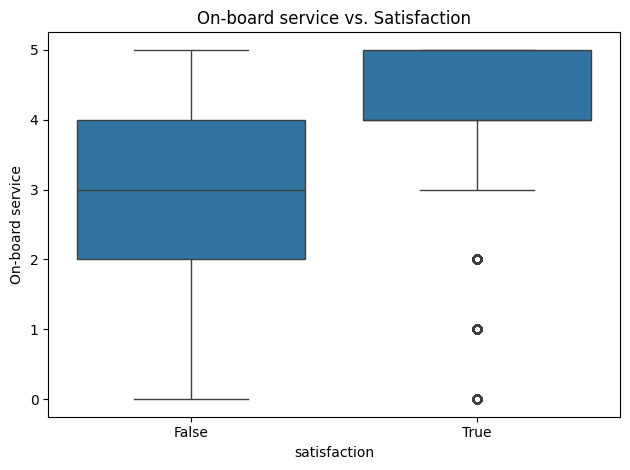

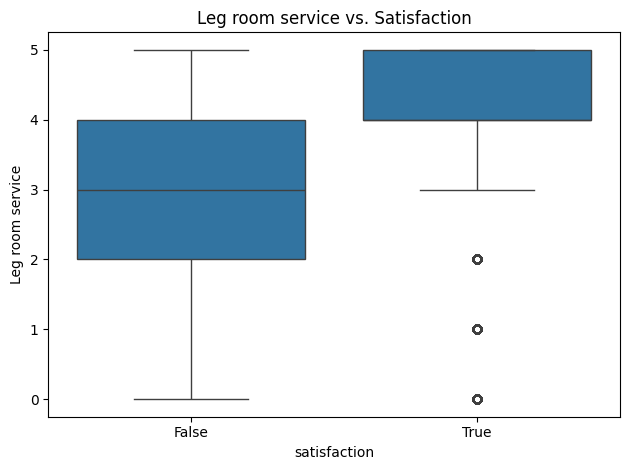

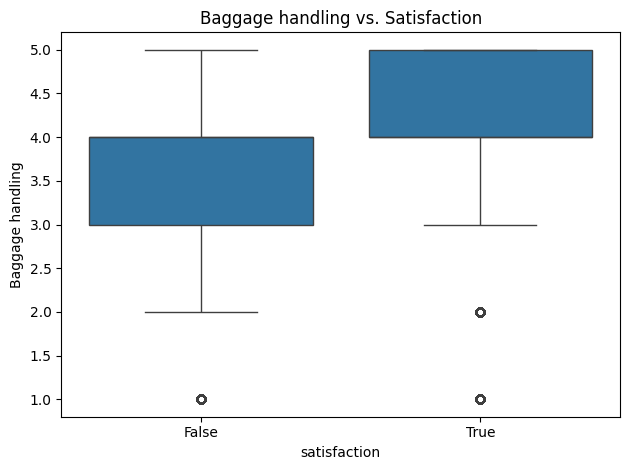

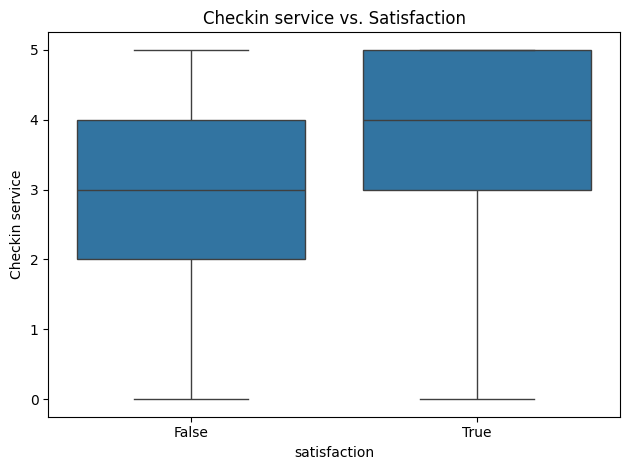

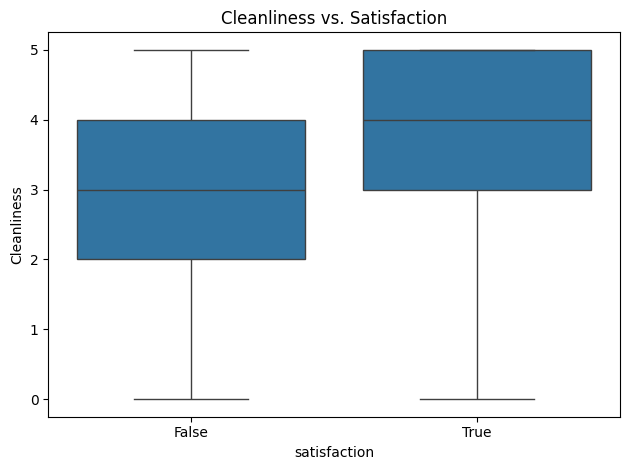

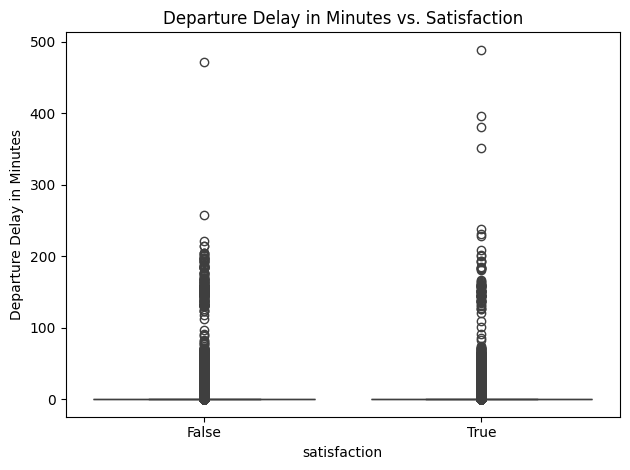

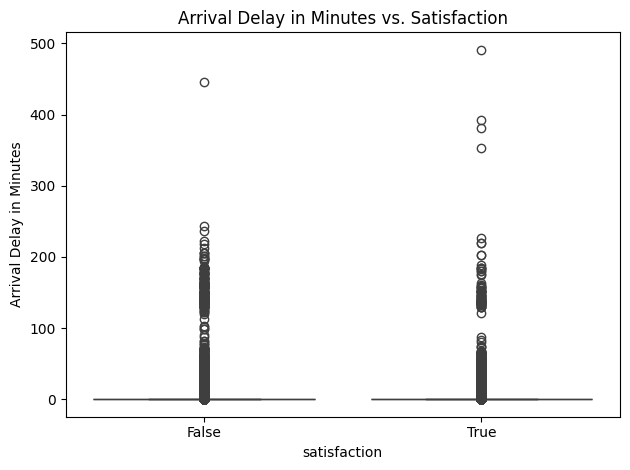

In [32]:
# Data Exploration
print(data.isna().sum()[data.isna().sum() > 0])   # columns with missing values
print(np.isinf(data.select_dtypes('number')).sum().loc[lambda s: s > 0])   # columns with inf
#The only variable with missing values is "Arrival Delay in Minutes". There are 292 missing values. There are no infinate values.

#Look at arrival and departure variables, as well as correlation of other variables
print(data.corr(numeric_only=True))

plt.scatter(data['Arrival Delay in Minutes'], data['Departure Delay in Minutes'])
plt.xlabel('Arrival Delay in Minutes')
plt.ylabel('Departure Delay in Minutes')
plt.title('Arrival Delay vs. Departure Delay')
plt.show()

#The arrival column is highly correlated with the departure column, so these are likely telling the same story.
#Drop arrival column from analysis (next block) since it's likely telling same story and doesn't really correlate with satisfaction. This gets rid of the need to fill in the missing values.
print(data.columns)
print(data.info())
print(data.describe())

#make sure the object's are seen as categories to use them in analysis
text_cols = data.select_dtypes(include=['object', 'string']).columns
for col in text_cols:
    data[col] = data[col].astype('category') #turn them into categories

# Examine response distribution
print(data['satisfaction'].value_counts())
print(data['satisfaction'].value_counts(normalize=True) * 100)

# Visualize response distribution
sns.countplot(data=data, x='satisfaction')
plt.title('Distribution of Passenger Satisfaction')
plt.xlabel('Satisfaction')
plt.ylabel('Number of Passengers')
plt.show()

#Overall, pretty equal groups. Slightly more reviews that aren't satisfied than satisfied. 56% unsatisfied, 44% satisfied.

# Histograms of numerical variables
data.hist(figsize=(16, 12), bins=20)
plt.tight_layout()
plt.show()
#many skewed left, overall not a lot of "normal" variables. However, none seem like there are huge outliers or anything crazy. No data entry mistakes noticed upon data exploration.

#Compare categorical variables with satisfaction (response variable)
categorical_cols = data.select_dtypes(include='category').columns

for col in categorical_cols:
    if col != 'satisfaction':
        sns.countplot(data=data, x=col, hue='satisfaction')
        plt.title(f'{col} vs. Satisfaction')
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

#Gender: no clear difference among gender
#Customer type: loyal customers seem more satisfied than disloyal customers (makes sense)
#Travel type: business travellers seem more satisfied than personal travellers
#Class: Business class seems more satisfied than eco and eco plus classes.

#Compare numerical variables with satisfaction (response variable)
numeric_cols = data.select_dtypes(include='number').columns

for col in numeric_cols:
    sns.boxplot(data=data, x='satisfaction', y=col)
    plt.title(f'{col} vs. Satisfaction')
    plt.tight_layout()
    plt.show()

#id: not related (that's good)
#age: satisfied customers appear to be slightly older than nonsatisfied customers
#flight distance: people on longer flights appear to be more satisfied than people on shorter flights
#inflight wifi service: people didn't seem to take this into account much, but the satisfied customers scored around a 3 on average where the nonsatisfied scored around a 2.5
#no difference in departure/arrival time convenient
#ease of online booking: satisfied customers tended to rate ease of online booking slightly higher, not much difference
#gate location: no difference
#food and drink: satisfied customers rated their food/drink options higher than nonsatisfied customers
#online boarding: satisfied customers rated online boarding much higher than nonsatisfied customers.
#seat comfort: satisfied customers rated seat comfort much higher than nonsatisfied customers.
#inflight entertainment: satisfied customers rate their infight entertainment higher than nonsatisfied customers
#on-board service: satisfied customers rated the on-board service higher
#leg room: satisfied customers rated the leg room higher
#baggage handling: satisfied customers rated baggage handling higher
#checkin service: satisfied customers rated the checkin service higher
#cleanliness: satisfied customers rated the cleanliness higher
#no clear difference/too many outliers on departure delay to tell
#no clear difference/too many outliers on arrival delay to tell

#Based on this exploration, I feel logistic regression may not be the best approach, as the variables are not very linear. Though, many variables do seem to somewhat relate with satisfaction.
#Those who do appear to relate seem to only have 1-2 points of difference, so unsure if this will actually show up clearly in the logistic regression.
#However, I will still start with that as a baseline as it is extremely easy to perform and explain before trying to fully grasp new ideas to improve my models.

## Model Comparisons

**Baseline Model**
* For the baseline model, I used multiple logistic regression.
* I included all variables, besides satisfaction, id, and arrival delay in minutes.

I began with a train/test split (70% train, 30% test)
* Logistic AUC: 0.9216

Following this, I performed 5-Fold Cross Validation on the original data, where I split the data into 5 random groups and used 4 of them to train a logistic regression model, and one to test the logistic model. I redid the baseline model to get a more comprehensive summary of the Logistic AUC Test Score.
* Logistic AUC: 0.9214 ± 0.0010

It turns out that these two models performed incredibly similar, but for consistency, I compared future models to the 5-Fold Cross Validation AUC, 0.9214.

**Attempt 1: Random Forest**
* For my first attempt, I used a random forest model.
* This again used all variables except satisfaction, id, and arrival delay in minutes.

Parameter Selection
* `n_estimators=100` - The model creates 100 decision trees. Random forests tend to have very similar estimates once `n_estimators` is large enough, and typically this is before 100. This ensures there are enough trees, but keeps the computation time down.
* `min_samples_leaf=10` - This ensures the model doesn't split too deeply. It means each leaf node within the tree must have at least 10 training samples. If a leaf node does not, then it doesn't split any further on that node, helping to reduce overfitting.
* `max_depth=20` - This limits each decision tree to a max of 20 levels deep. This also helps against overfiting, as it caps the depth from becoming too complex. While 20 feels like a lot, with so many observations, we are able to fit a more flexible model; the deeper the tree, the closer the tree can get to the data.
* `n_jobs=-1` - This instructs the computer to use all available CPU cores to build the trees at once, helping to significantly speed up the process by training many trees simultaneously.
* `random_state=1` - Sets a random seed so results are replicable.

I also looked at which features were the most important within this model, shown below:
* 0.2162: Online boarding
* 0.1113: Class[Eco]
* 0.1087: Inflight wifi service
* 0.1068: Type of Travel[Personal Travel]
* 0.0862: Inflight entertainment

The 5 most important features for building the trees (the variables used the most times) were Online Boarding, Class[Eco], Inflight Wifi Service, Type of Travel[Personal Travel] and Inflight Entertainment. This model used 4 random variables to predict each decision tree. This helped to ensure the trees were all different from each other, rather than creating the same tree 100 times. Using less variables in this way helps to prevent overfitting.

I obtained a comprehensive AUC score for the random forest model:
* Random Forest AUC: 0.9568

This AUC score is much higher than my baseline (~0.035 higher), showing that it does better predict the satisfaction.

**Attempt 2: Light GBM Model**

Following my successful attempt at random forests, I decided to delve deeper than our class and explore a newer, effective version of a decision tree: Light GBM Models.

LightGBM Models (Light Gradient Boosting Machines) are designed to be highly efficient, especially with large datasets. They work like other gradient boosters, building one tree at a time sequentially based on the previous tree. It wants to correct the errors that the previous tree made.

It also uses leaf-wise tree growth, meaning it grows vertically (leaf-wise) rather than horizontally (level-wise) like traditional trees. It only splits the leaf that would reduce the most loss, allowing it to capture complex patterns and converge faster. However, it tends to overfit much more than traditional decision trees.

It also tends to evaluate bins of values, like a histogram, rather than every single point, which speeds up the computation time.

Basically, it's a typically GBM, but faster, with the downside of potentially overfitting easier.

Parameter Selection
* `n_estimators=500` - The more decision trees, the more the model learns and can correct. However, this also can lead to overfitting, which is why the next parameter is important.
* `learning_rate=0.05` - This is a low learning rate to help ensure the decision trees learn slowly. This helps to slow down the likelihood of overfitting, as too fast of learning + too many trees = fitting to noise. Keeping this small makes the trees learn less each run.
* `num_leaves=63` - This is the standard, robust choice. This helps to control the complexity of the tree, helping to capture high-degree interactions without overfitting as easily.
* `n_jobs=-1 & random_state=1` - These were explained in my Attempt 1 parameter explanation, the explanations remain the same for this model.

I obtained a comprehensive AUC score for the LightGBM Model:
* LightGBM AUC: 0.9584

This AUC score is much higher than my baseline (\~.037 higher) and is higher than my random forest model (\~0.0024 higher), showing that it does better predict the satisfaction than both previous attempts.

**Further Testing**

Following this success, I wanted to explore LightGBM Models a bit more, so I began exploring the parameter. I began by increasing the number of trees more (to 1500) while decreasing the learning rate (to 0.02) to see if this would help, hurt, or have little effect on the model. It had little effect on the LightGBM model, with the AUC only increasing by 0.0005 (less than the standard error of either model). This model took much longer to run (about 3x the time), so I ultimately decided to continue using the first LightGBM model. I also felt this model might have overfit the data slightly due to the high number of trees.

Overall, I ultimately decided to use my original Attempt 2 - LightGBM model for the predictions, leaving me with an overall Kaggle Score of 0.95897 in 2966th place out of 3734 submissions.

In [33]:
#prepare the X_train, X_test, y_train, y_test variables, start with logistic regression of everything
allvars = data.columns.drop(['satisfaction', 'id', 'Arrival Delay in Minutes'])
design = MS(allvars)
X = design.fit_transform(data)
y = data.satisfaction == True

#Just use train/test set for first attempt
X_train, X_test, y_train, y_test = train_test_split(X,
                                                    y,
                                                    test_size=0.3,
                                                    random_state=1)
#Perform the logistic regression model
glm_train = sm.GLM(y_train,
                   X_train,
                   family=sm.families.Binomial())
results = glm_train.fit()
probs = results.predict(exog=X_test)

#Get the results for the "test" dataset
labels = np.array([0]*len(probs))
labels[probs>0.5] = 1

#Create confusion table
print("Confusion Table:")
print(confusion_table(labels, y_test))
print(f"Test Accuracy: {np.mean(labels == y_test):.4f}")
print(f"Test Error Rate: {np.mean(labels != y_test):.4f}")

# Confusion Table:
# Truth       False  True
# Predicted
# False      105255  14230
# True        11368  79038
# Test Accuracy: 0.8780
# Test Error Rate: 0.1220

#Now look at the AUC Score since that's what this is 'graded' on:
auc = roc_auc_score(y_test, probs)
print(f"Logistic AUC: {auc:.4f}")

/usr/local/lib/python3.13/dist-packages/sklearn/base.py:918: FutureWarning: ModelSpec will move to its own package in ISLP 0.7. `from ISLP.models import ModelSpec` (and the other tools of ISLP.models that build model matrices) will keep working, but other import paths, such as ISLP.models.model_spec, may not, and `intercept` will then default to False. This ModelSpec relies on the default of `intercept`, now True, which adds a column of ones named 'intercept' to the design: only statsmodels' models (OLS, GLM, ...) need it, as glmstar's estimators and most scikit-learn estimators fit the intercept themselves. Pass intercept=True to keep it (e.g. for statsmodels), or intercept=False to drop it.
  return self.fit(X, **fit_params).transform(X)


Confusion Table:
Truth       False  True 
Predicted               
False      105255  14230
True        11368  79038
Test Accuracy: 0.8780
Test Error Rate: 0.1220
Logistic AUC: 0.9216


In [34]:
#Try to do logistic regression again using 5 k-folds instead of just train/test

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

X_cv = X.drop(columns='intercept')   # sklearn adds its own intercept
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
scores = cross_val_score(logit, X_cv, y, cv=skf, scoring='roc_auc', n_jobs=-1)
print(f"Logistic AUC: {scores.mean():.4f} ± {scores.std():.4f}")

#Create confusion table
print("Confusion Table:")
print(confusion_table(labels, y_test))
print(f"Test Accuracy: {np.mean(labels == y_test):.4f}")
print(f"Test Error Rate: {np.mean(labels != y_test):.4f}")

Logistic AUC: 0.9214 ± 0.0010
Confusion Table:
Truth       False  True 
Predicted               
False      105255  14230
True        11368  79038
Test Accuracy: 0.8780
Test Error Rate: 0.1220


In [35]:
#Attempt 1: Random forest model
from sklearn.ensemble import RandomForestClassifier

#100 trees, 10 min sample, 20 depth
#use sqrt(p) predictors (default) (Also done prior to lab about decision trees)
rf = RandomForestClassifier(n_estimators=100, min_samples_leaf=10,
                            max_depth=20, n_jobs=-1, random_state=1)
scores = cross_val_score(rf, X_cv, y, cv=skf, scoring='roc_auc', verbose=2)
print(f"RF AUC: {scores.mean():.4f} ± {scores.std():.4f}")
#AUC did much better here, 0.9568 > 0.9214, random forest worked great!

rf.fit(X_cv, y)
imp = pd.Series(rf.feature_importances_, index=X_cv.columns).sort_values(ascending=False)
print(imp.head(10))
#top variables: online boarding, class[eco], inflight wifi service, type of travel[personal travel] and inflight entertainment.

[CV] END .................................................... total time= 2.4min
[CV] END .................................................... total time= 2.2min
[CV] END .................................................... total time= 2.4min
[CV] END .................................................... total time= 2.2min
[CV] END .................................................... total time= 2.9min
RF AUC: 0.9568 ± 0.0007


[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed: 12.1min finished


Online boarding                     0.216186
Class[Eco]                          0.111290
Inflight wifi service               0.108659
Type of Travel[Personal Travel]     0.106755
Inflight entertainment              0.086214
Seat comfort                        0.069100
Flight Distance                     0.052896
Customer Type[disloyal Customer]    0.040609
Ease of Online booking              0.033280
On-board service                    0.032990
dtype: float64


In [41]:
# Let's inspect the exact column count of X_cv and what the RF model is using
print(f"Number of columns in X_cv (after dummy variables): {X_cv.shape[1]}")
print("Columns:", list(X_cv.columns))

# Get the max_features value from the trained Random Forest model
# If it is 'sqrt', it will use the square root of the number of columns in X_cv
max_features_value = rf.max_features
print(f"\nRandom Forest max_features parameter: {max_features_value}")

if max_features_value == 'sqrt' or max_features_value == 'auto':
    import math
    calc_m = math.isqrt(X_cv.shape[1])
    print(f"Number of variables randomly considered at each split (m): {calc_m}")


Number of columns in X_cv (after dummy variables): 21
Columns: ['Age', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Gender[Male]', 'Customer Type[disloyal Customer]', 'Type of Travel[Personal Travel]', 'Class[Eco]', 'Class[Eco Plus]']

Random Forest max_features parameter: sqrt
Number of variables randomly considered at each split (m): 4


In [36]:
#LightGBM Model (Attempt 2)
import lightgbm as lgb
import re

def clean_names(df):
    df = df.copy()
    df.columns = [re.sub(r'[^0-9a-zA-Z_]+', '_', c) for c in df.columns]
    return df

# --- Cross-validation ---
X_lgb = clean_names(X_cv)

#500 trees, 0.05 learning rate
lgbm = lgb.LGBMClassifier(n_estimators=500, learning_rate=0.05,
                          num_leaves=63, n_jobs=-1, random_state=1,
                          verbose=-1)
scores = cross_val_score(lgbm, X_lgb, y, cv=skf, scoring='roc_auc')
print(f"LGBM AUC: {scores.mean():.4f} ± {scores.std():.4f}")

LGBM AUC: 0.9584 ± 0.0008


Top 10 Predictors in LightGBM (Normalized Gain Importance summing to 1.0):


,0
Online_boarding,0.518638
Type_of_Travel_Personal_Travel_,0.135281
Inflight_wifi_service,0.127360
Inflight_entertainment,0.036418
Customer_Type_disloyal_Customer_,0.027607
Checkin_service,0.022915
Class_Eco_,0.019861
Baggage_handling,0.016984
On_board_service,0.015437
Flight_Distance,0.014342


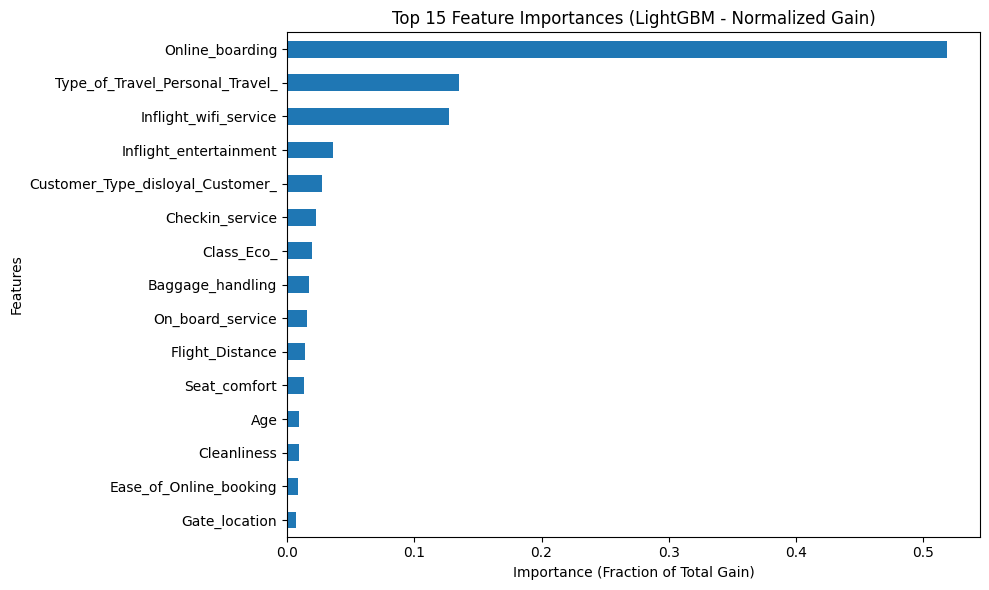

In [44]:
# Calculate and plot normalized (gain-based) feature importances for LightGBM
import pandas as pd
import matplotlib.pyplot as plt

# Fit the model on the full cleaned data first
lgbm.fit(X_lgb, y)

# Retrieve raw gain importances (total information gain contributed by each feature)
raw_gain_importances = lgbm.booster_.feature_importance(importance_type='gain')

# Normalize them so they sum up to 1.0 (just like Random Forest!)
normalized_importances = raw_gain_importances / raw_gain_importances.sum()

# Create a pandas Series
lgb_imp = pd.Series(normalized_importances, index=X_lgb.columns).sort_values(ascending=False)

print("Top 10 Predictors in LightGBM (Normalized Gain Importance summing to 1.0):")
display(lgb_imp.head(10))

# Plot the normalized feature importances
plt.figure(figsize=(10, 6))
lgb_imp.head(15).plot(kind='barh').invert_yaxis()
plt.title('Top 15 Feature Importances (LightGBM - Normalized Gain)')
plt.xlabel('Importance (Fraction of Total Gain)')
plt.ylabel('Features')
plt.tight_layout()
plt.show()

In [37]:
#more trees, less learning rate?

#way slower. do not re-run.
lgbm2 = lgb.LGBMClassifier(n_estimators=1500, learning_rate=0.02,
                           num_leaves=63, min_child_samples=50,
                           subsample=0.8, subsample_freq=1,
                           colsample_bytree=0.8,
                           n_jobs=-1, random_state=1, verbose=-1)
scores2 = cross_val_score(lgbm2, X_lgb, y, cv=skf, scoring='roc_auc')
print(f"LGBM2 AUC: {scores2.mean():.4f} ± {scores2.std():.4f}")

LGBM2 AUC: 0.9589 ± 0.0009


## Model interpretation – How can this help with Customer Satisfaction?

The top five important predictors are as follows:
* 0.5186: Online boarding
* 0.1353: Type of Travel[Personal Travel]
* 0.1274: Inflight wifi service
* 0.0364: Inflight entertainment
* 0.0276: Customer Type[Disloyal Customer]

Overall, Online Boarding is by far the most important predictor. Over 50% of the information gain is by this variable.

Based on this, there are a few key takeaways of how to interpret this model. While we can predict customer satisfaction based on their previous ratings, there are also things we can do to help ensure more customers will be satisfied:
* Online Boarding and Inflight Wifi Service are both in the top five important predictors. Customers likely value a strong, easy digital experience when boarding and on the flight. By improving both of these, customers are more likely to be more satisfied.
* The context of travel matters. The type of travel (especially if it's personal) greatly impacts a customer's satisfaction. They tend to be less satisfieed. Customers who are flying for work tend to be more satisfied, so the airline may have to work harder on personal vacations to ensure satisfaction is met.
* Inflight Entertainment and Inflight Wifi Service are both crucial features. Passengers likely value their physical comfort while flying, as these both have a strong influence on whether or not a customer is satisfied. Ensuring the entertainment and wifi is up to standards on flights may help to increase the satisfaction in the future.
* Since the most important thing is online boarding, ensure online boarding is set up for all flights and that it is efficient and effortless for all passengers to ensure satisfaction.



## Reflection of the Project

Overall, this project was a huge success. Many things worked, but there were also some things that did not.

**What went well?**

My LightGBM model performed much better than the baseline logistic regression. I also was able to learn about LightGBM, and I was able to dive much deeper into random forests than previously, especially since much of the coding was completed before the recent lab.

In addition, I was able to use Gemini, Claude, and ChatGPT to explain models to me, help me find predictors, and explain why those predictors were good. Using AI in this way to assist me was very helpful, especially with learning a new model in a very short period of time.

Overall, I feel the project as a whole went very well. I was able to predict airline satisfaction at a very high rate, and I was able to learn and fully understand new models. I wanted to ensure the models I chose were understandable, rather than only performing well. In a real-world setting, I feel I could explain what my model is doing and how it works to other people interested in this airline satisfaction data. This wouldn't be the case with some of the very strong, winning models with the level of understanding I currently have.

**What went poorly?**

A lot of my tweaking of models went worse than I expected. I anticipated tweaking the parameters of my LightGBM model to improve it a lot more than it did, and unfortunately this wasn't the case.

In addition, I was attempting to understand some feature engineering to average some ratings, creating less overall predictors for the LightGBM model. Unfortunately, I wasn't grasping it. While Gemini did create a working model, I struggled to explain or justify it. It again performed at about the same level as the other two LightGBM models. Because of my lack of understanding of the code, I decided to delete it rather than use it, as I would be unable to explain what was going on.

One final thing that went poorly was my time management. I greatly underestimated the amount of time this project would require. I anticipated it taking a few hours to do the Kaggle submission, and a few more hours for the write-up. I didn't realize quite how long it takes to run code on a real dataset, and I wish I had given myself more time towards this project. I think I could have learned a lot more and grown my model to perform much better if I had given myself this extra time.

**Future Analysis:**

If I had more time for this, I would try to understand some of the models that broke 0.96. I'm proud of where I came within this project, but so many people performed so much better than me using models I haven't even heard of. With more time, I could explore their models to better understand what each model is doing and when it tends to work best. I also want to look into LightGBM more to discover if it often tends to outperform random forests, or if this just happened to be the case in this example.

If you have any further questions about my analysis, please feel free to reach out to me via GitHub or at my email: roggiebear2005@gmail.com. Thank you!

In [40]:
# --- Prepare test data the same way as training data ---
# for col in text_cols.drop('satisfaction', errors='ignore'):
#     test_data[col] = pd.Categorical(test_data[col],
#                                     categories=data[col].cat.categories)

# test_X = design.transform(test_data).drop(columns='intercept')
# test_X = clean_names(test_X)

# # --- Fit on all training data and predict ---
# lgbm.fit(X_lgb, y)
# preds = lgbm.predict_proba(test_X)[:, 1]

# submission = pd.DataFrame({'id': test_data['id'], 'satisfaction': preds})
# submission.to_csv('submission.csv', index=False)